Buildings of the study area extruded to their estimated height and colored by their dominant
facade material, with the attributes of `building_attributes_extraction.ipynb`.

I wanted a second map colored by the material areas, but the areas of a building are its percentages times
its facade area, so the dominant material is the same one either way. The areas are in the exported table.

In [1]:
import json
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd

from imageable.visualization.data_visualization import plot_grouped_distribution_bars
from imageable.visualization.footprints import visualize_heights, visualize_materials

/Users/legariapena.j/Documents/imageable-2026/imageable/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/legariapena.j/Documents/imageable-2026/imageable/.venv/lib/python3.13/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [2]:
ATTRIBUTES_PATH = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_04_building_attributes")

ATTRIBUTES_TABLE_PATH = ATTRIBUTES_PATH/Path("building_attributes.parquet")
VISUALIZATIONS_PATH = ATTRIBUTES_PATH/Path("visualizations")
VISUALIZATIONS_PATH.mkdir(parents = True, exist_ok = True)

gdf_attributes = gpd.read_parquet(ATTRIBUTES_TABLE_PATH)

print(f"Buildings: {len(gdf_attributes)}")
print(f"Columns: {len(gdf_attributes.columns)}")

Buildings: 2456
Columns: 83


### Materials back into dictionaries

The extraction saved one column per material so that the table could be written to disk, and
`visualize_materials` wants a dictionary.

In [3]:
percentage_columns = [column for column in gdf_attributes.columns if column.startswith("material_pct_")]
material_names = [column.replace("material_pct_", "") for column in percentage_columns]

print(f"Materials: {len(material_names)}")


def get_material_dictionaries(gdf, columns, names):
    dictionaries = []
    for i in range(0,len(gdf)):
        dictionary = {}
        for j in range(0,len(columns)):
            value = gdf[columns[j]].iloc[i]
            if(pd.notna(value)):
                dictionary[names[j]] = float(value)

        dictionaries.append(dictionary)

    return dictionaries


def get_dominant_material(dictionary):
    if(len(dictionary) == 0 or max(dictionary.values()) <= 0):
        return None

    return max(dictionary.items(), key = lambda item: item[1])[0]


percentage_dictionaries = get_material_dictionaries(gdf_attributes, percentage_columns, material_names)

gdf_attributes["material_percentages"] = percentage_dictionaries

Materials: 20


### The maps

In [4]:
PARENT_IMAGES = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/"
"data/2026_08_03_imagery_quality_assessment/images")

drawn_mask = gdf_attributes["building_height"] > 0

gdf_for_map = gdf_attributes.loc[
    drawn_mask,
    ["building_id", "building_height", "material_percentages", "geometry"]
]

print(f"Buildings drawn: {len(gdf_for_map)} of {len(gdf_attributes)}")

# visualize_materials pairs this list with the features by position, so it is built from the
# same rows and in the same order that to_json writes them.
building_image_paths = [
    str(PARENT_IMAGES/Path(building_id)/Path("image.jpg"))
    for building_id in gdf_for_map["building_id"]
]

found = sum(1 for path in building_image_paths if Path(path).exists())
print(f"Images found: {found} of {len(building_image_paths)}")

# Both functions write into the properties of the dictionary they are given, so each map gets
# its own, otherwise the height map inherits the encoded images of the material map.
geojson_for_map = json.loads(gdf_for_map.to_json())
geojson_for_heights = json.loads(gdf_for_map.to_json())

Buildings drawn: 2053 of 2456


Images found: 2053 of 2053


In [5]:
visualize_materials(
    geojson_for_map,
    material_dict_column = "material_percentages",
    height_column = "building_height",
    paths_building_images = building_image_paths,
    save_html = str(VISUALIZATIONS_PATH/Path("materials_3d.html"))
)

visualize_heights(
    geojson_for_heights,
    height_column = "building_height",
    save_html = str(VISUALIZATIONS_PATH/Path("heights_3d.html"))
)

print(f"Saved the maps to {VISUALIZATIONS_PATH}")

Saved the maps to /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_04_building_attributes/visualizations


### Dominant material of the study area

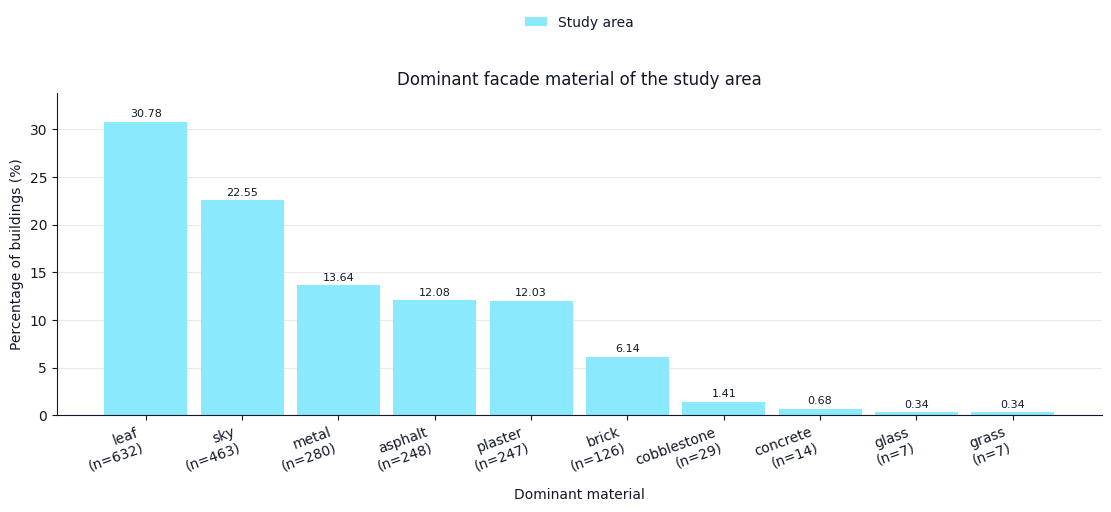

(<Figure size 1100x500 with 1 Axes>,
 <Axes: title={'center': 'Dominant facade material of the study area'}, xlabel='Dominant material', ylabel='Percentage of buildings (%)'>)

In [6]:
gdf_attributes["dominant_material"] = [get_dominant_material(d) for d in percentage_dictionaries]

counts = gdf_attributes[drawn_mask]["dominant_material"].value_counts()
dominant_materials = list(counts.index)
percentages = [100*counts[material]/counts.sum() for material in dominant_materials]

plot_grouped_distribution_bars(
    groups = dominant_materials,
    model_names = ["Study area"],
    rmse = [percentages],
    counts = list(counts),
    order = "input",
    title = "Dominant facade material of the study area",
    x_label = "Dominant material",
    y_label = "Percentage of buildings (%)",
    figsize = (11.0, 5.0),
    savepath = str(VISUALIZATIONS_PATH/Path("dominant_material_counts.png"))
)